In [332]:

# Step 1: Importing Libraries

# Data manipulation
import pandas as pd  # Load and manage the aviation dataset
import numpy as np  # Perform numerical operations

# Data visualization
import matplotlib.pyplot as plt  # Create graphs and charts
import seaborn as sns  # Create statistical visualizations and heatmaps

# Data preprocessing
from sklearn.model_selection import train_test_split  # Divide data into training and testing sets
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # Standardize numerical features for Logistic Regression
                                                                # Convert categorical values into numerical features
from sklearn.impute import SimpleImputer  # Handle missing values
from sklearn.compose import ColumnTransformer  # Apply different preprocessing to numerical and categorical columns
from sklearn.pipeline import Pipeline  # Combine preprocessing and model training into a workflow

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,  # Display precision, recall, F1-score, and support
    confusion_matrix  # Show correct and incorrect predictions
)

# Hyperparameter tuning
from sklearn.model_selection import GridSearchCV  # Find better model parameters

print("All libraries imported successfully!")


All libraries imported successfully!


In [333]:
# Step 2: Load the Dataset and Understand Its Structure

# Load the Dataset

df = pd.read_excel("/content/aviation_flight_delay_synthetic_10000_realistic_v2.xlsx")

In [334]:
# Display first 5 rows
df.head()

,Flight_ID,Airline,Flight_Date,Day_of_Week,Month,Origin_Airport,Origin_Region,Destination_Airport,Distance_km,Scheduled_Departure,...,Delay_Minutes,Actual_Departure,Actual_Arrival,Aircraft_Type,Booking_Load_Pct,Crew_Experience_Years,Previous_Flight_Delay_Min,Holiday_Flag,Maintenance_Flag,Ticket_Price_INR
0,FL100000,Akasa Air,2024-02-12,Monday,2,BOM,West,BLR,830,10:50,...,22,2024-02-12 11:12,2024-02-12 16:10,Airbus A320,67.9,6.0,0.0,0,0,3980.0
1,FL100001,Air India Express,2025-01-14,Tuesday,1,AMD,West,BOM,440,09:30,...,22,2025-01-14 09:52,2025-01-14 14:48,Airbus A320,78.7,29.2,35.0,0,0,2361.0
2,FL100002,Air India,2024-05-09,Thursday,5,AMD,West,BLR,1220,16:20,...,0,2024-05-09 16:20,2024-05-09 21:25,Boeing 737,58.8,4.0,0.0,0,0,4600.0
3,FL100003,Air India Express,2024-03-29,Friday,3,AMD,West,COK,1490,23:55,...,0,2024-03-29 23:55,2024-03-30 04:49,Airbus A320,84.4,7.4,0.0,0,0,5319.0
4,FL100004,IndiGo,2024-09-07,Saturday,9,HYD,South,DEL,1270,11:10,...,100,2024-09-07 12:50,2024-09-07 17:46,Airbus A321,64.1,10.9,28.0,0,1,3321.0


In [335]:
# Flight_ID: Unique identifier assigned to each flight record.
# Airline: Name of the airline operating the flight.
# Flight_Date: Scheduled date of the flight.
# Day_of_Week: Day of the week on which the flight is scheduled.
# Month: Month in which the flight is scheduled.
# Origin_Airport: Airport from which the flight departs.
# Origin_Region: Geographical region of the departure airport.
# Destination_Airport: Airport where the flight is scheduled to arrive.
# Distance_km: Distance between the origin and destination airports in kilometers.
# Scheduled_Departure: Scheduled departure time of the flight.
# Departure_Hour: Hour of the day when the flight is scheduled to depart.
# Scheduled_Duration_Min: Planned flight duration in minutes.
# Weather_Condition: Weather conditions associated with the flight.
# Weekend_Flag: Indicates whether the flight is scheduled on a weekend.
# Flight_Delayed: Target variable indicating whether the flight was delayed (Yes/No).
# Delay_Minutes: Number of minutes the flight was delayed.
# Actual_Departure: Actual departure time of the flight.
# Actual_Arrival: Actual arrival time of the flight.
# Aircraft_Type: Type of aircraft used for the flight.
# Booking_Load_Pct: Percentage of the flight's booking capacity that is booked.
# Crew_Experience_Years: Experience of the flight crew in years.
# Previous_Flight_Delay_Min: Delay in minutes associated with the previous flight.
# Holiday_Flag: Indicates whether the flight date falls on a holiday.
# Maintenance_Flag: Indicates whether a maintenance issue or flag is recorded for the flight.
# Ticket_Price_INR: Ticket price in Indian rupees.

In [336]:
# Check dataset dimensions
print("Number of rows and columns:", df.shape)

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])


Number of rows and columns: (10000, 25)
Total rows: 10000
Total columns: 25


In [337]:
# Display column names
print(df.columns.tolist())

['Flight_ID', 'Airline', 'Flight_Date', 'Day_of_Week', 'Month', 'Origin_Airport', 'Origin_Region', 'Destination_Airport', 'Distance_km', 'Scheduled_Departure', 'Departure_Hour', 'Scheduled_Duration_Min', 'Weather_Condition', 'Weekend_Flag', 'Flight_Delayed', 'Delay_Minutes', 'Actual_Departure', 'Actual_Arrival', 'Aircraft_Type', 'Booking_Load_Pct', 'Crew_Experience_Years', 'Previous_Flight_Delay_Min', 'Holiday_Flag', 'Maintenance_Flag', 'Ticket_Price_INR']


In [338]:
# Check dataset information
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Flight_ID                  10000 non-null  object 
 1   Airline                    10000 non-null  object 
 2   Flight_Date                10000 non-null  object 
 3   Day_of_Week                10000 non-null  object 
 4   Month                      10000 non-null  int64  
 5   Origin_Airport             10000 non-null  object 
 6   Origin_Region              9900 non-null   object 
 7   Destination_Airport        10000 non-null  object 
 8   Distance_km                10000 non-null  int64  
 9   Scheduled_Departure        10000 non-null  object 
 10  Departure_Hour             10000 non-null  int64  
 11  Scheduled_Duration_Min     10000 non-null  int64  
 12  Weather_Condition          9750 non-null   object 
 13  Weekend_Flag               10000 non-null  int6

In [339]:
# Statistical summary of numerical columns
df.describe()


,Month,Distance_km,Departure_Hour,Scheduled_Duration_Min,Weekend_Flag,Flight_Delayed,Delay_Minutes,Booking_Load_Pct,Crew_Experience_Years,Previous_Flight_Delay_Min,Holiday_Flag,Maintenance_Flag,Ticket_Price_INR
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,9800.000000,9820.000000,9750.000000,10000.000000,10000.000000,9850.000000
mean,6.452300,997.447000,13.395800,109.858500,0.280000,0.260500,13.933700,78.788316,10.211792,16.814154,0.017100,0.076100,3124.708223
std,3.418639,494.552839,4.504195,40.102542,0.449021,0.438929,29.007093,12.410703,5.625012,29.002978,0.129651,0.265171,978.779623
min,1.000000,150.000000,5.000000,45.000000,0.000000,0.000000,0.000000,35.000000,0.500000,0.000000,0.000000,0.000000,1200.000000
25%,4.000000,520.000000,10.000000,74.000000,0.000000,0.000000,0.000000,70.200000,6.100000,0.000000,0.000000,0.000000,2425.250000
50%,6.000000,910.000000,13.000000,105.000000,0.000000,0.000000,0.000000,79.000000,9.200000,0.000000,0.000000,0.000000,3108.000000
75%,9.000000,1380.000000,17.000000,143.000000,1.000000,1.000000,11.000000,87.900000,13.200000,27.000000,0.000000,0.000000,3785.750000
max,12.000000,2050.000000,23.000000,213.000000,1.000000,1.000000,240.000000,100.000000,30.000000,240.000000,1.000000,1.000000,7194.000000


In [340]:
# Check unique values in selected columns
print("Airlines:", df["Airline"].unique())
print("Weather conditions:", df["Weather_Condition"].unique())
print("Target values (Flight_Delayed):", df["Flight_Delayed"].unique())


Airlines: ['Akasa Air' 'Air India Express' 'Air India' 'IndiGo' 'Vistara' 'SpiceJet']
Weather conditions: ['Clear' 'Cloudy' 'Rain' 'Thunderstorm' nan 'Fog']
Target values (Flight_Delayed): [1 0]


In [341]:
# Step 3: Data Quality Checks


# Check missing values in each column
df.isnull().sum()

,0
Flight_ID,0
Airline,0
Flight_Date,0
Day_of_Week,0
Month,0
Origin_Airport,0
Origin_Region,100
Destination_Airport,0
Distance_km,0
Scheduled_Departure,0


In [342]:
# Display columns with missing values
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

print(missing_values)

Origin_Region                100
Weather_Condition            250
Aircraft_Type                120
Booking_Load_Pct             200
Crew_Experience_Years        180
Previous_Flight_Delay_Min    250
Ticket_Price_INR             150
dtype: int64


In [343]:
# Count duplicate rows
print("Total duplicate rows:", df.duplicated().sum())


Total duplicate rows: 0


In [344]:

# Check unique values in selected columns
print("Flight_Delayed:")
print(df["Flight_Delayed"].value_counts(dropna=False))

print("\nWeekend_Flag:")
print(df["Weekend_Flag"].value_counts(dropna=False))

print("\nHoliday_Flag:")
print(df["Holiday_Flag"].value_counts(dropna=False))

print("\nMaintenance_Flag:")
print(df["Maintenance_Flag"].value_counts(dropna=False))


Flight_Delayed:
Flight_Delayed
0    7395
1    2605
Name: count, dtype: int64

Weekend_Flag:
Weekend_Flag
0    7200
1    2800
Name: count, dtype: int64

Holiday_Flag:
Holiday_Flag
0    9829
1     171
Name: count, dtype: int64

Maintenance_Flag:
Maintenance_Flag
0    9239
1     761
Name: count, dtype: int64


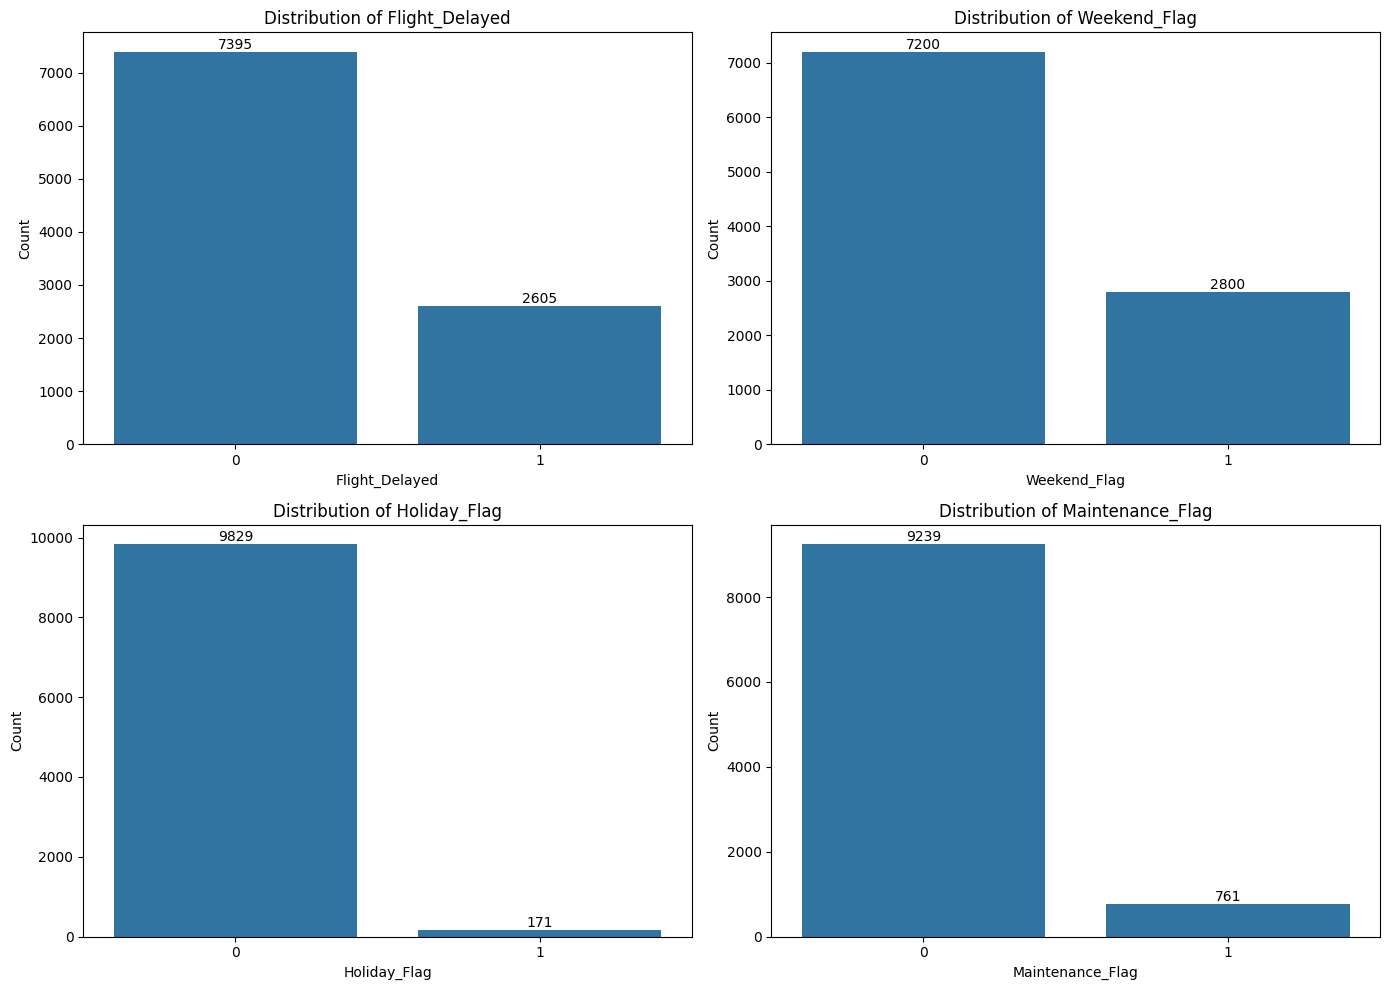

In [345]:

columns = [
    "Flight_Delayed",
    "Weekend_Flag",
    "Holiday_Flag",
    "Maintenance_Flag"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, column in zip(axes.flatten(), columns):
    sns.countplot(data=df, x=column, ax=ax)

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Count")

    for container in ax.containers:
        ax.bar_label(container)

plt.tight_layout()
plt.show()


In [346]:
# Step 4: Data Cleaning

# Select columns required for the project

# We will exclude Flight_ID because it is an identifier and exclude Delay_Minutes, Actual_Departure, and Actual_Arrival.

required_columns = [
    "Flight_Date",
    "Airline",
    "Day_of_Week",
    "Month",
    "Origin_Airport",
    "Origin_Region",
    "Destination_Airport",
    "Distance_km",
    "Scheduled_Departure",
    "Departure_Hour",
    "Scheduled_Duration_Min",
    "Weather_Condition",
    "Weekend_Flag",
    "Flight_Delayed",
    "Aircraft_Type",
    "Booking_Load_Pct",
    "Crew_Experience_Years",
    "Previous_Flight_Delay_Min",
    "Holiday_Flag",
    "Maintenance_Flag",
    "Ticket_Price_INR"
]

df = df[required_columns].copy()

print("Required columns selected successfully!")



Required columns selected successfully!


In [347]:
# Remove rows where the target is missing
df = df.dropna(subset=["Flight_Delayed"])

print("Missing target values removed.")
print("Dataset shape:", df.shape)
print("Missing values remaining:", df.isnull().sum().sum())



Missing target values removed.
Dataset shape: (10000, 21)
Missing values remaining: 1250


In [348]:
# Check remaining missing values
print(df.isnull().sum().sum())

1250


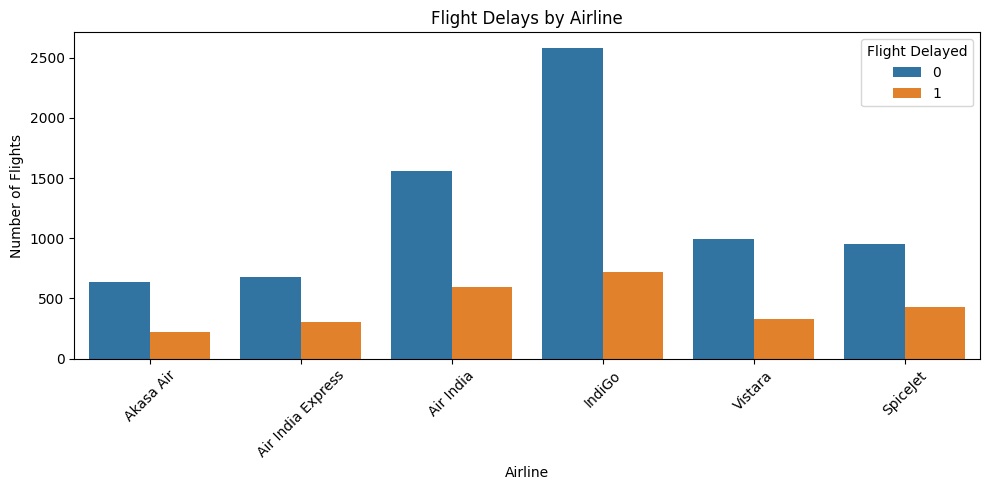

In [349]:
# Step 5: Exploratory Data Analysis (EDA)



# Flight delays by airline

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Airline",
    hue="Flight_Delayed"
)

plt.title("Flight Delays by Airline")
plt.xlabel("Airline")
plt.ylabel("Number of Flights")
plt.xticks(rotation=45)
plt.legend(title="Flight Delayed")

plt.tight_layout()
plt.show()


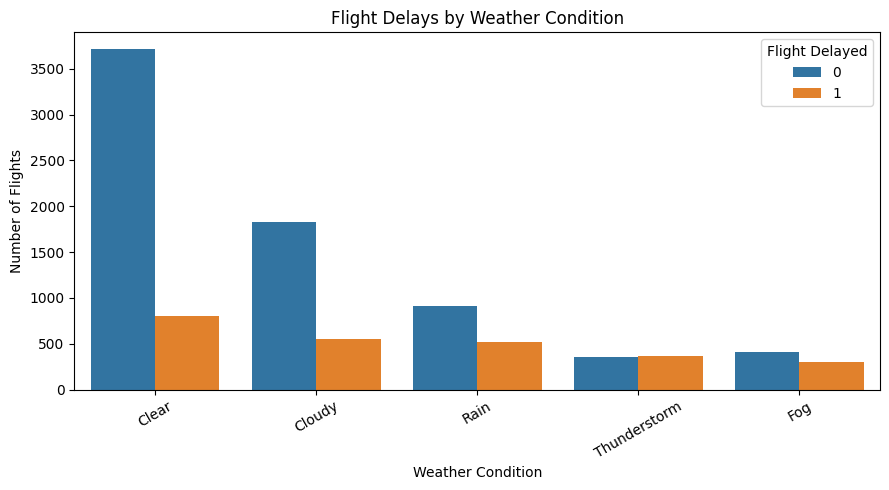

In [350]:

# Flight delays by weather condition

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Weather_Condition",
    hue="Flight_Delayed"
)

plt.title("Flight Delays by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Number of Flights")
plt.xticks(rotation=30)
plt.legend(title="Flight Delayed")

plt.tight_layout()
plt.show()


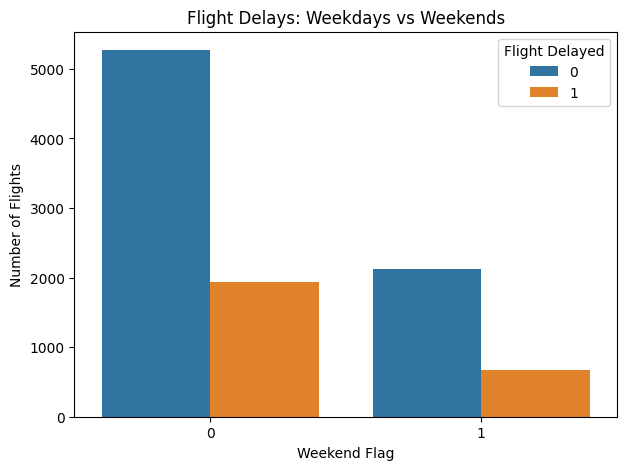

In [351]:

# Flight delays by weekend

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Weekend_Flag",
    hue="Flight_Delayed"
)

plt.title("Flight Delays: Weekdays vs Weekends")
plt.xlabel("Weekend Flag")
plt.ylabel("Number of Flights")
plt.legend(title="Flight Delayed")

plt.show()


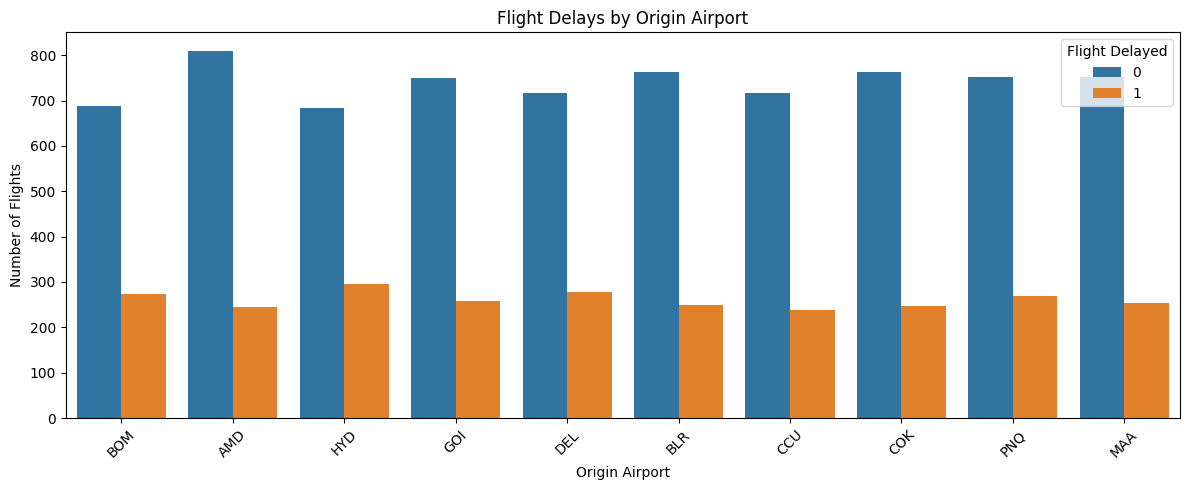

In [352]:

# Flight delays by origin airport

plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="Origin_Airport",
    hue="Flight_Delayed"
)

plt.title("Flight Delays by Origin Airport")
plt.xlabel("Origin Airport")
plt.ylabel("Number of Flights")
plt.xticks(rotation=45)
plt.legend(title="Flight Delayed")

plt.tight_layout()
plt.show()


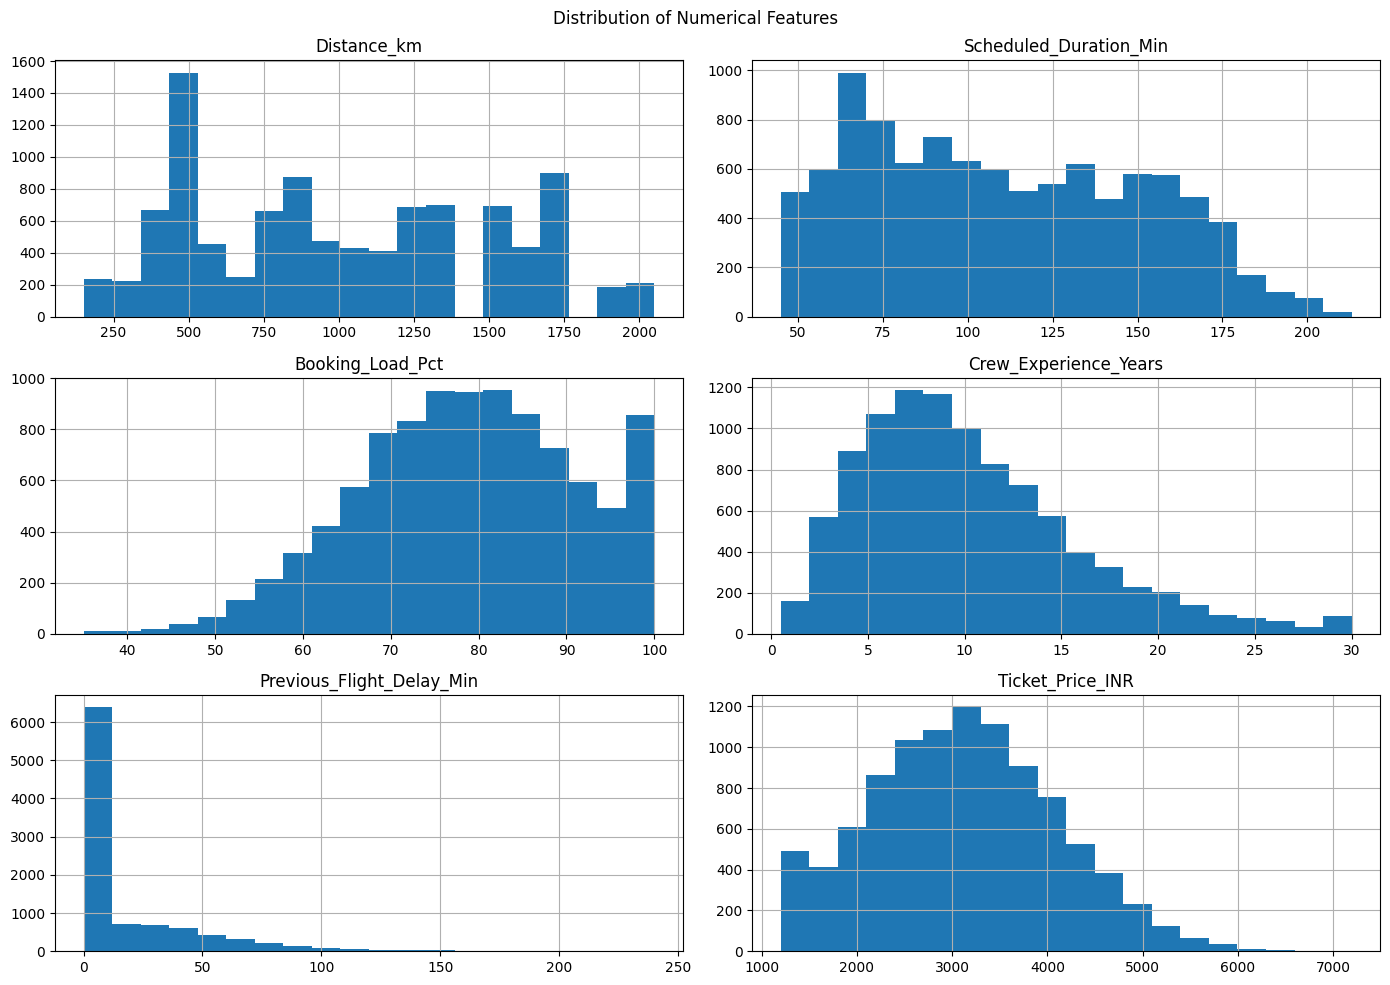

In [353]:

# Distribution of numerical features

numeric_features = [
    "Distance_km",
    "Scheduled_Duration_Min",
    "Booking_Load_Pct",
    "Crew_Experience_Years",
    "Previous_Flight_Delay_Min",
    "Ticket_Price_INR"
]

df[numeric_features].hist(
    figsize=(14, 10),
    bins=20
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()


In [354]:
# Step 6 — Feature Selection and Defining X and y


# Select numerical columns for correlation analysis
correlation_data = df.select_dtypes(include=np.number)

# Create correlation matrix
correlation_matrix = correlation_data.corr()

# Display correlation with the target
print(
    correlation_matrix["Flight_Delayed"]
    .sort_values(ascending=False)
)


Flight_Delayed               1.000000
Maintenance_Flag             0.100326
Previous_Flight_Delay_Min    0.096254
Departure_Hour               0.023621
Booking_Load_Pct             0.022503
Ticket_Price_INR             0.006180
Holiday_Flag                 0.002556
Month                        0.001384
Crew_Experience_Years       -0.008082
Distance_km                 -0.013250
Scheduled_Duration_Min      -0.015337
Weekend_Flag                -0.027605
Name: Flight_Delayed, dtype: float64


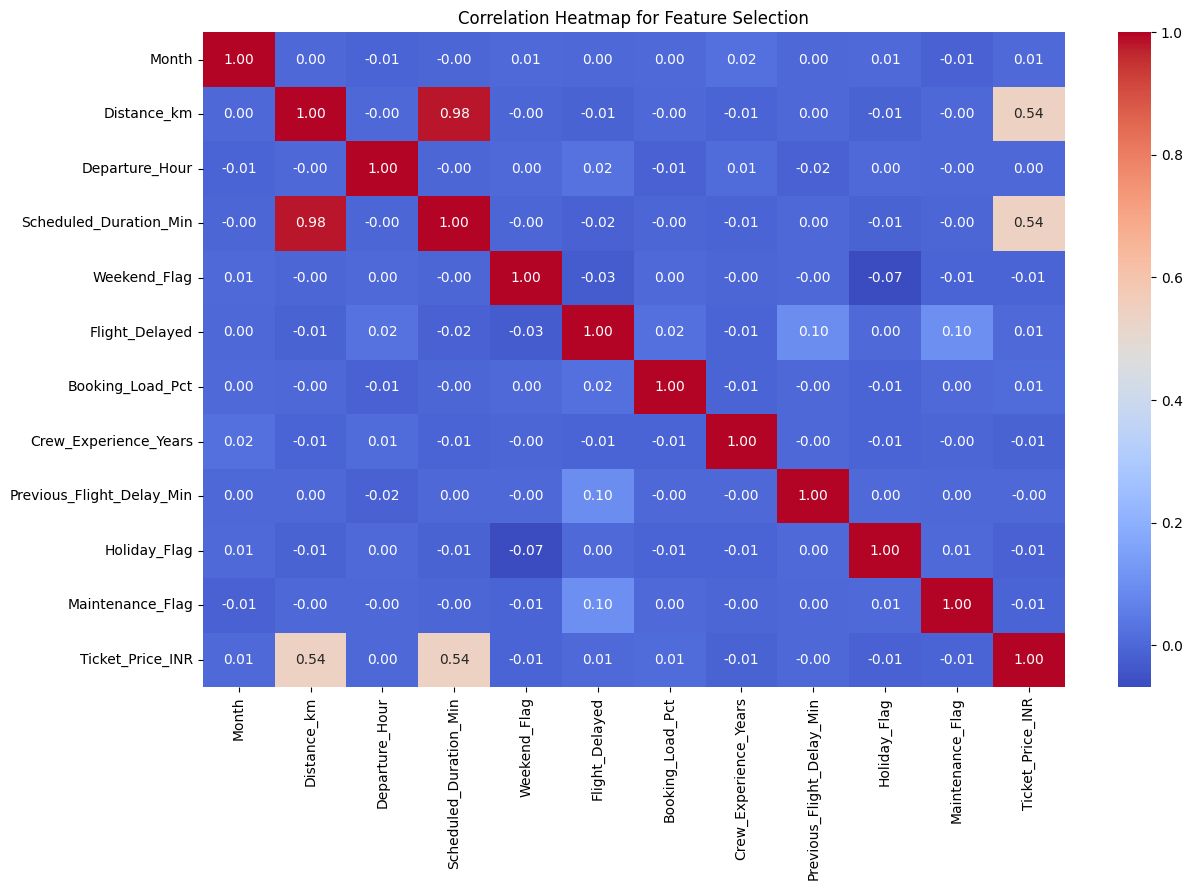

In [355]:

# Correlation heatmap including the numerical target

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap for Feature Selection")
plt.tight_layout()
plt.show()


In [356]:
# Define input features (X)


# Removed Flight_ID
# Removed Flight_Delayed as it is our target(y).
# Removed Month and Holiday_Flag aslo as there correlation with Flight_Delayed is zero(0)
# Since Departure_Hour, Day_of_Week already exist,we have excluded Flight_Date and Scheduled_Departure.
# Also, exclude Delay_Minutes, Actual_Departure, and Actual_Arrival from the prediction features to prevent data leakage.
feature_columns = [
    "Airline",
    "Day_of_Week",
    "Origin_Airport",
    "Origin_Region",
    "Destination_Airport",
    "Distance_km",
    "Departure_Hour",
    "Scheduled_Duration_Min",
    "Weather_Condition",
    "Weekend_Flag",
    "Aircraft_Type",
    "Booking_Load_Pct",
    "Crew_Experience_Years",
    "Previous_Flight_Delay_Min",
    "Maintenance_Flag",
    "Ticket_Price_INR"
]


X = df[feature_columns]

# Define target (y)
y = df["Flight_Delayed"]

print("Input features:", X.shape)
print("Target:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Input features: (10000, 16)
Target: (10000,)

Target distribution:
Flight_Delayed
0    7395
1    2605
Name: count, dtype: int64


In [357]:
# Step 7: Split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y   # Keeps approximately the same proportion of delayed and non-delayed flights in both sets.
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8000, 16)
X_test: (2000, 16)
y_train: (8000,)
y_test: (2000,)


In [358]:
# Step 8: Identify numerical and categorical columns

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)


Numerical features:
['Distance_km', 'Departure_Hour', 'Scheduled_Duration_Min', 'Weekend_Flag', 'Booking_Load_Pct', 'Crew_Experience_Years', 'Previous_Flight_Delay_Min', 'Maintenance_Flag', 'Ticket_Price_INR']

Categorical features:
['Airline', 'Day_of_Week', 'Origin_Airport', 'Origin_Region', 'Destination_Airport', 'Weather_Condition', 'Aircraft_Type']


In [359]:
# Step 9: Preprocessing


# Create preprocessing pipelines

# Numerical preprocessing
numeric_preprocessor = Pipeline([           # Combines multiple processing steps into a single workflow.
    ("imputer", SimpleImputer(strategy="median")), # Fills missing numerical values using the median.
    ("scaler", StandardScaler())  # Standardizes numerical features for Logistic Regression.
])

# Categorical preprocessing
categorical_preprocessor = Pipeline([           # Combines multiple processing steps into a single workflow.
    ("imputer", SimpleImputer(strategy="most_frequent")), # Fills missing categorical values using the most common category.
    ("encoder", OneHotEncoder(handle_unknown="ignore"))  # Converts categories into binary columns and safely handles unseen categories.
])

# Combine preprocessing for Logistic Regression
preprocessor_lr = ColumnTransformer([                   # Applies the appropriate preprocessing to each column type.
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

# Combine preprocessing for Random Forest
preprocessor_rf = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

print("Preprocessing pipelines created successfully!")


Preprocessing pipelines created successfully!


In [360]:
# Step 10: Build and Train the Machine Learning Models



# Logistic Regression pipeline

lr_model = Pipeline([
    ("preprocessing", preprocessor_lr),
    ("model", LogisticRegression(max_iter=2000))  # allows the model more iterations to converge during training.
])

print("Logistic Regression pipeline created!")


Logistic Regression pipeline created!


In [361]:
# Random Forest pipeline

rf_model = Pipeline([
    ("preprocessing", preprocessor_rf),
    ("model", RandomForestClassifier(
        n_estimators=100, # the forest contains 100 trees.
        random_state=42  # makes the model's random choices reproducible.
    ))
])

print("Random Forest pipeline created!")


Random Forest pipeline created!


In [362]:
# Train Logistic Regression

lr_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

# Train Random Forest
rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")


Logistic Regression trained successfully!
Random Forest trained successfully!


In [363]:
# Step 11 — Make Predictions

y_pred_lr = lr_model.predict(X_test)

y_pred_rf = rf_model.predict(X_test)

print("Predictions completed!")


Predictions completed!


In [364]:
# Step 12 — Evaluate both models using Accuracy, Precision, Recall, and F1-score


# Logistic Regression
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)

# Random Forest
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)

# Display results
print("Logistic Regression - Before Tuning")
print("Accuracy :", round(lr_accuracy, 3))  # How many predictions were correct overall
print("Precision:", round(lr_precision, 3))  # Of the flights predicted as delayed, how many actually were delayed?
print("Recall   :", round(lr_recall, 3))   # Of all flights that actually were delayed, how many did the model identify?
print("F1-score :", round(lr_f1, 3))  # Balance between precision and recall

print("\nRandom Forest - Before Tuning")
print("Accuracy :", round(rf_accuracy, 3))
print("Precision:", round(rf_precision, 3))
print("Recall   :", round(rf_recall, 3))
print("F1-score :", round(rf_f1, 3))


Logistic Regression - Before Tuning
Accuracy : 0.761
Precision: 0.694
Recall   : 0.148
F1-score : 0.244

Random Forest - Before Tuning
Accuracy : 0.747
Precision: 0.59
Recall   : 0.094
F1-score : 0.162


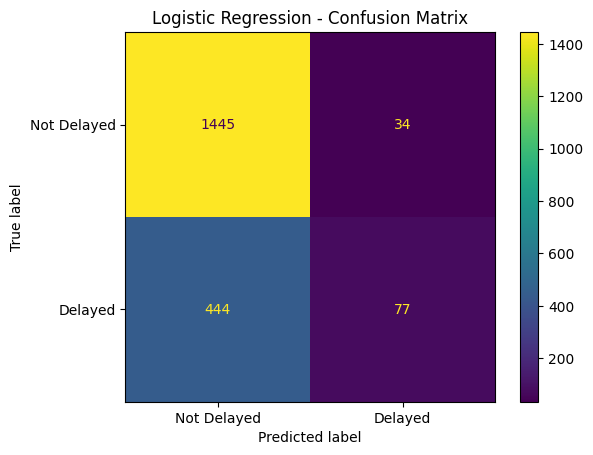

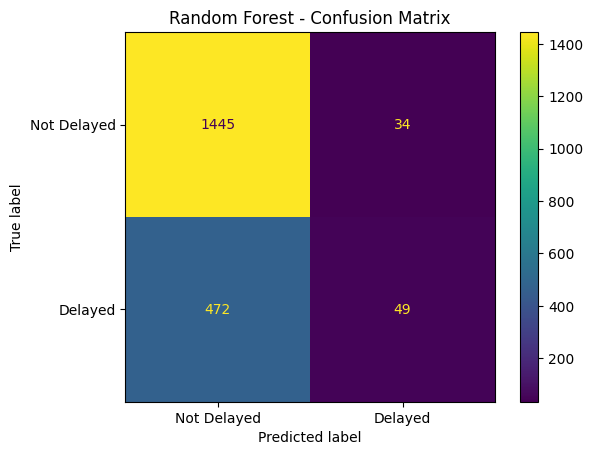

In [365]:
# Step 13 — Check the Confusion Matrix

from sklearn.metrics import ConfusionMatrixDisplay

# Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    display_labels=["Not Delayed", "Delayed"],
    values_format="d"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()


# Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["Not Delayed", "Delayed"],
    values_format="d"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()


In [366]:
# Step 14 — Hyperparameter Tuning using GridSearchCV

# try different model settings to find better-performing versions.

# Define Logistic Regression pipeline
lr_tuning_pipeline = Pipeline([                         # Connects preprocessing and model training into one workflow.
    ("preprocessing", preprocessor_lr),
    ("model", LogisticRegression(max_iter=2000))        # creates the classifier and allows up to 2,000 iterations for optimization.
])

# Define parameters to test
lr_param_grid = {
    "model__C": [0.01, 0.1, 1, 10],    # C controls the strength of regularization in Logistic Regression. (0.01 -	Stronger regularization) (10 -	Weaker regularization)
                                       # Regularization helps control model complexity and reduce overfitting.
                                       # A smaller C applies stronger regularization.
    "model__class_weight": [None, "balanced"]   # None: treats the classes with equal weight per observation.
                                                # "balanced": automatically assigns greater weight to the less frequent class.
}

# Perform hyperparameter tuning
lr_grid = GridSearchCV(                # Tests different parameter combinations using cross-validation. # automatically refitted each best pipeline on the full training dataset.
    estimator=lr_tuning_pipeline,     # The complete pipeline that will be trained.
    param_grid=lr_param_grid,         # The combinations of parameters to test.
    scoring="f1",                     # Selects settings based on the F1-score.
    cv=5,                             # Uses five-fold cross-validation.
    n_jobs=-1                         # Uses all available CPU cores where supported
)

lr_grid.fit(X_train, y_train)

print("Best Logistic Regression Parameters:")
print(lr_grid.best_params_)

print("Best Cross-Validation F1-score:")
print(round(lr_grid.best_score_, 3))


Best Logistic Regression Parameters:
{'model__C': 0.01, 'model__class_weight': 'balanced'}
Best Cross-Validation F1-score:
0.461


In [367]:

# Define Random Forest pipeline
rf_tuning_pipeline = Pipeline([
    ("preprocessing", preprocessor_rf),
    ("model", RandomForestClassifier(random_state=42))
])

# Define parameters to test
rf_param_grid = {
    "model__n_estimators": [100, 200],  # Number of decision trees in the forest.
    "model__max_depth": [None, 10, 20],  # Maximum depth of each tree. None allows growth until other stopping conditions apply.
    "model__min_samples_split": [2, 5],  # Minimum number of samples needed to split a node.
    "model__class_weight": [None, "balanced"]  # Tests whether balancing class weights improves the minority class.
}

# Perform hyperparameter tuning
rf_grid = GridSearchCV(
    estimator=rf_tuning_pipeline,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("Best Cross-Validation F1-score:")
print(round(rf_grid.best_score_, 3))


Best Random Forest Parameters:
{'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best Cross-Validation F1-score:
0.413


In [368]:
# Logistic Regression performed better than Random Forest during hyperparameter tuning.

In [369]:
# Step 15: Compare Tuned Models on Test Data

# Get the best tuned models
best_lr_model = lr_grid.best_estimator_
best_rf_model = rf_grid.best_estimator_

# Make predictions on the test set
y_pred_lr_tuned = best_lr_model.predict(X_test)
y_pred_rf_tuned = best_rf_model.predict(X_test)

print("Tuned model predictions completed!")


Tuned model predictions completed!


In [370]:
# Calculate metrics for both tuned models
tuned_results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr_tuned),
        accuracy_score(y_test, y_pred_rf_tuned)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr_tuned, zero_division=0),
        precision_score(y_test, y_pred_rf_tuned, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr_tuned, zero_division=0),
        recall_score(y_test, y_pred_rf_tuned, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_lr_tuned, zero_division=0),
        f1_score(y_test, y_pred_rf_tuned, zero_division=0)
    ]
})

print(tuned_results.round(3))


                 Model  Accuracy  Precision  Recall  F1-score
0  Logistic Regression     0.656      0.395   0.601     0.476
1        Random Forest     0.713      0.443   0.397     0.419


In [371]:
# Regression has the higher F1-score and recall, while Random Forest has the higher accuracy and precision.

# Logistic Regression: Detects 60.1% of actual delayed flights. It is the stronger choice if identifying delays is your main priority.
# Random Forest: Has higher accuracy and precision, but misses more actual delays.
# Overall: Logistic Regression is currently the stronger model for balancing precision and recall, as measured by F1-score.

In [372]:
# Step 16: Compare Models Before and After Tuning

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Logistic Regression",
        "Random Forest",
        "Random Forest"
    ],
    "Stage": [
        "Before Tuning",
        "After Tuning",
        "Before Tuning",
        "After Tuning"
    ],
    "Accuracy": [
        lr_accuracy, 0.656,
        rf_accuracy, 0.713
    ],
    "Precision": [
        lr_precision, 0.395,
        rf_precision, 0.443
    ],
    "Recall": [
        lr_recall, 0.601,
        rf_recall, 0.397
    ],
    "F1-score": [
        lr_f1, 0.476,
        rf_f1, 0.419
    ]
})

print(comparison.round(3).to_string(index=False))


              Model         Stage  Accuracy  Precision  Recall  F1-score
Logistic Regression Before Tuning     0.761      0.694   0.148     0.244
Logistic Regression  After Tuning     0.656      0.395   0.601     0.476
      Random Forest Before Tuning     0.747      0.590   0.094     0.162
      Random Forest  After Tuning     0.713      0.443   0.397     0.419


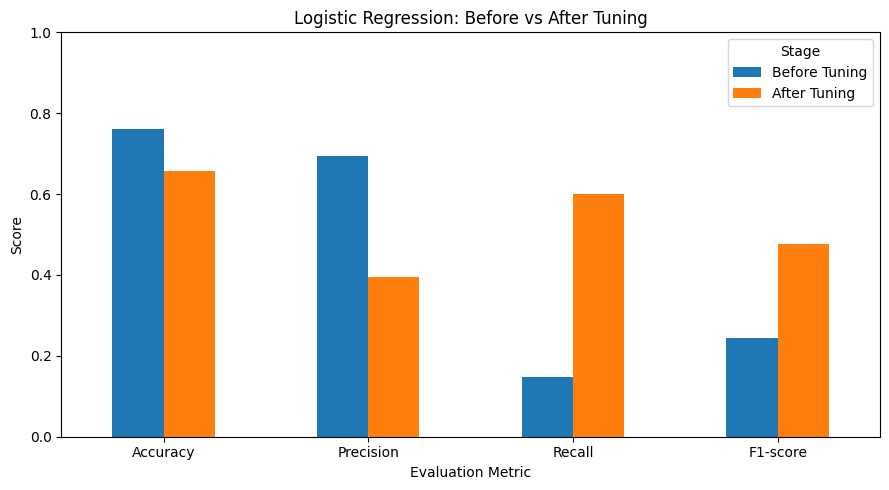

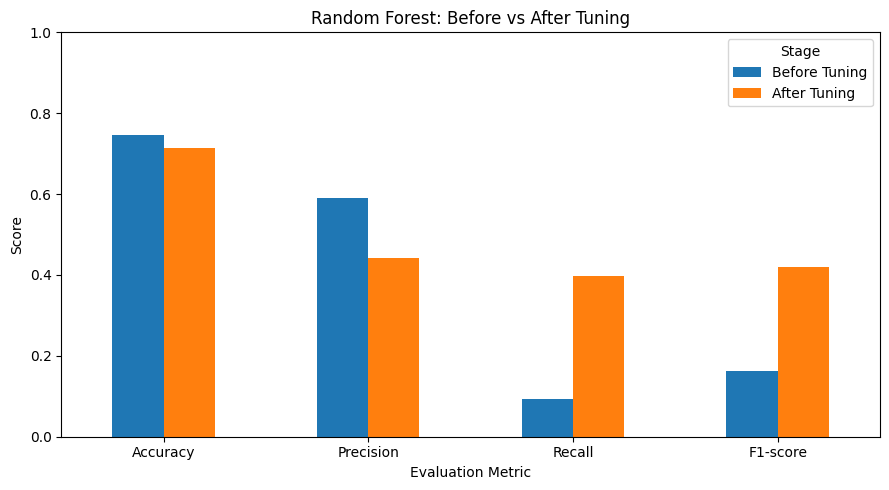

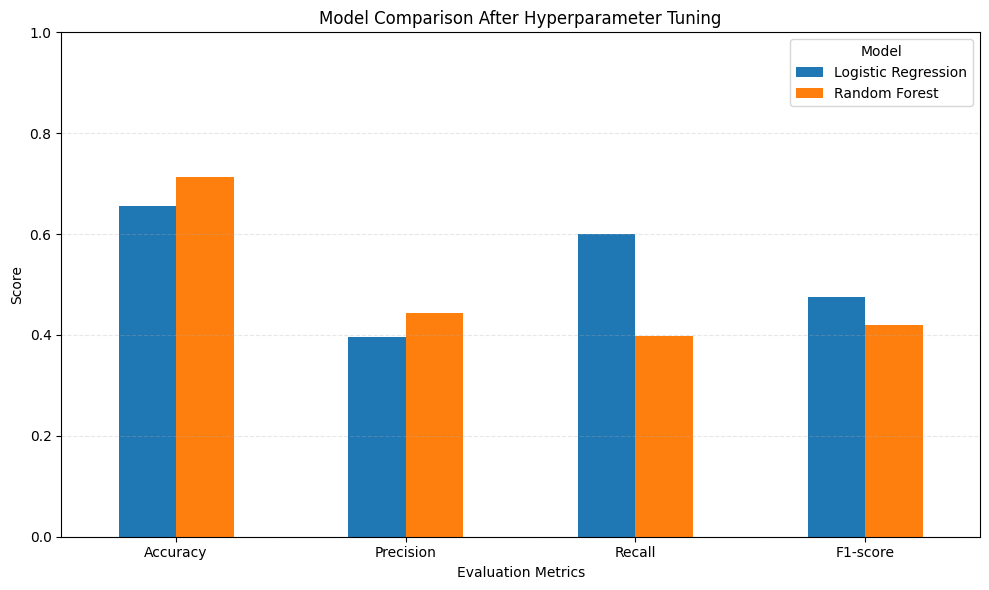

In [373]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

for model_name in ["Logistic Regression", "Random Forest"]:
    model_data = comparison[comparison["Model"] == model_name]

    ax = model_data.set_index("Stage")[metrics].T.plot(
        kind="bar",
        figsize=(9, 5)
    )

    ax.set_title(f"{model_name}: Before vs After Tuning")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.set_xlabel("Evaluation Metric")
    plt.xticks(rotation=0)
    plt.legend(title="Stage")
    plt.tight_layout()
    plt.show()




# Results after hyperparameter tuning
tuned_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Logistic Regression": [0.656, 0.395, 0.601, 0.476],
    "Random Forest": [0.713, 0.443, 0.397, 0.419]
})

# Create comparison chart
tuned_comparison.set_index("Metric").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Comparison After Hyperparameter Tuning")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


In [374]:
# Logistic Regression is currently preferable if your main objective is to identify delayed flights,
# because it has higher recall and F1-score.

# Random Forest is more accurate overall, but misses more actual delays.